In [2]:
from pathlib import Path
import pandas as pd

RAW = Path("TrafficLabelling")

for f in sorted(RAW.glob("*.csv")):
    print(f.name, "|", round(f.stat().st_size / 1e6), "MB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv | 96 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | 102 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv | 75 MB
Monday-WorkingHours.pcap_ISCX.csv | 269 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv | 109 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv | 92 MB
Tuesday-WorkingHours.pcap_ISCX.csv | 175 MB
Wednesday-workingHours.pcap_ISCX.csv | 286 MB


In [3]:
monday = RAW / "Monday-WorkingHours.pcap_ISCX.csv"
df = pd.read_csv(monday, encoding="latin-1", low_memory=False)
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns.tolist())

(529918, 85)
['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag 

In [4]:
df.head()

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,4,2,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
1,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
2,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
3,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
4,192.168.10.14-8.253.185.121-49486-80-6,8.253.185.121,80,192.168.10.14,49486,6,03/07/2017 08:56:22,3,2,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN


In [5]:
dfs = []
for f in sorted(RAW.glob("*.csv")):
    d = pd.read_csv(f, encoding="latin-1", low_memory=False)
    d.columns = d.columns.str.strip()
    d["day_file"] = f.name
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)

print(df.shape)
print(df["Label"].value_counts(dropna=False))

(3119345, 86)
Label
BENIGN                        2273097
NaN                            288602
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack  Brute Force         1507
Web Attack  XSS                  652
Infiltration                       36
Web Attack  Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [6]:
empty = df[df["Label"].isna()]
print(empty["day_file"].value_counts())
print(empty.notna().sum().sum())   # count of non-empty cells in those rows

df = df.dropna(subset=["Label"]).reset_index(drop=True)
print(df.shape)

day_file
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv    288602
Name: count, dtype: int64
288602
(2830743, 86)


In [7]:
df["Label"] = df["Label"].str.replace("\x96", "-", regex=False).str.strip()

print(df["Label"].unique())

pd.crosstab(df["Label"], df["day_file"])

<StringArray>
[                    'BENIGN',                       'DDoS',
                   'PortScan',                        'Bot',
               'Infiltration',   'Web Attack - Brute Force',
           'Web Attack - XSS', 'Web Attack - Sql Injection',
                'FTP-Patator',                'SSH-Patator',
              'DoS slowloris',           'DoS Slowhttptest',
                   'DoS Hulk',              'DoS GoldenEye',
                 'Heartbleed']
Length: 15, dtype: str


day_file,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,Friday-WorkingHours-Morning.pcap_ISCX.csv,Monday-WorkingHours.pcap_ISCX.csv,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,Tuesday-WorkingHours.pcap_ISCX.csv,Wednesday-workingHours.pcap_ISCX.csv
Label,,,,,,,,
BENIGN,97718,127537,189067,529918,288566,168186,432074,440031
Bot,0,0,1966,0,0,0,0,0
DDoS,128027,0,0,0,0,0,0,0
DoS GoldenEye,0,0,0,0,0,0,0,10293
DoS Hulk,0,0,0,0,0,0,0,231073
DoS Slowhttptest,0,0,0,0,0,0,0,5499
DoS slowloris,0,0,0,0,0,0,0,5796
FTP-Patator,0,0,0,0,0,0,7938,0
Heartbleed,0,0,0,0,0,0,0,11


In [8]:
import numpy as np

num = df.select_dtypes(include="number")

bad = pd.DataFrame({
    "inf": np.isinf(num).sum(),
    "nan": num.isna().sum(),
    "negative": (num < 0).sum(),
})

bad[(bad > 0).any(axis=1)]

,inf,nan,negative
Flow Duration,0,0,115
Flow Bytes/s,1509,1358,85
Flow Packets/s,2867,0,115
Flow IAT Mean,0,0,115
Flow IAT Max,0,0,115
Flow IAT Min,0,0,2891
Fwd IAT Min,0,0,17
Fwd Header Length,0,0,35
Bwd Header Length,0,0,22
Fwd Header Length.1,0,0,35


In [9]:
broken = (
    np.isinf(num).any(axis=1)
    | num.isna().any(axis=1)
    | (df["Flow Duration"] < 0)
    | (df["Flow IAT Min"] < 0)
    | (df["Fwd Header Length"] < 0)
    | (df["Bwd Header Length"] < 0)
)

print(broken.sum())
df.loc[broken, "Label"].value_counts()

5792


Label
BENIGN           4508
DoS Hulk         1108
PortScan          126
DDoS               21
Bot                10
FTP-Patator         7
DoS GoldenEye       5
Heartbleed          4
SSH-Patator         2
Infiltration        1
Name: count, dtype: int64

In [10]:

fix_cols = ["Flow IAT Min", "Fwd IAT Min", "Fwd Header Length",
            "Bwd Header Length", "Fwd Header Length.1", "min_seg_size_forward"]
for c in fix_cols:
    df[c] = df[c].clip(lower=0)


rates = ["Flow Bytes/s", "Flow Packets/s"]
drop = (
    np.isinf(df[rates]).any(axis=1)
    | df[rates].isna().any(axis=1)
    | (df["Flow Duration"] < 0)
)
print(df.loc[drop, "Label"].value_counts())

df = df[~drop].reset_index(drop=True)
print(df.shape)
print("Heartbleed left:", (df["Label"] == "Heartbleed").sum())

Label
BENIGN         1892
DoS Hulk        949
PortScan        126
Bot              10
FTP-Patator       3
DDoS              2
Name: count, dtype: int64
(2827761, 86)
Heartbleed left: 11


In [11]:
nunique = df.nunique()
print(nunique[nunique <= 1])

Bwd PSH Flags           1
Bwd URG Flags           1
Fwd Avg Bytes/Bulk      1
Fwd Avg Packets/Bulk    1
Fwd Avg Bulk Rate       1
Bwd Avg Bytes/Bulk      1
Bwd Avg Packets/Bulk    1
Bwd Avg Bulk Rate       1
dtype: int64


In [12]:
dead = nunique[nunique <= 1].index.tolist() + ["Fwd Header Length.1"]
df = df.drop(columns=dead)
print(df.shape)

feat = df.columns.drop(["Flow ID", "Source IP", "Source Port", "Destination IP",
                        "Destination Port", "Protocol", "Timestamp", "Label", "day_file"])

dup_rows = df.duplicated(subset=feat).sum()
dup_conflict = df.groupby(list(feat))["Label"].nunique()
print("duplicate feature rows:", dup_rows)
print("feature rows with conflicting labels:", (dup_conflict > 1).sum())

(2827761, 77)
duplicate feature rows: 594443
feature rows with conflicting labels: 268


In [16]:
df_full = df.copy()   # everything kept, conflicts included

conflict_keys = dup_conflict[dup_conflict > 1].index
is_conflict = df.set_index(list(feat)).index.isin(conflict_keys)

df_flow = (
    df[~is_conflict]
    .drop_duplicates(subset=list(feat) + ["Label"])
    .reset_index(drop=True)
)

print("full:", df_full.shape, " flow-level:", df_flow.shape)

full: (2827761, 77)  flow-level: (2233050, 77)


In [14]:
counts = pd.DataFrame({
    "full": df_full["Label"].value_counts(),
    "flow": df_flow["Label"].value_counts(),
})
counts["flow_%"] = (counts["flow"] / counts["full"] * 100).round(1)
counts

,full,flow,flow_%
Label,,,
BENIGN,2270027,1896826,83.6
Bot,1836,1413,77.0
DDoS,128019,128011,100.0
DoS GoldenEye,10293,10286,99.9
DoS Hulk,225242,172713,76.7
DoS Slowhttptest,5499,5228,95.1
DoS slowloris,5794,5383,92.9
FTP-Patator,7935,5931,74.7
Heartbleed,11,11,100.0


In [15]:
lost = pd.DataFrame({
    "before": df["Label"].value_counts(),
    "after_conflict": df_full["Label"].value_counts(),
})
lost["removed"] = lost["before"] - lost["after_conflict"]
lost["kept_%"] = (lost["after_conflict"] / lost["before"] * 100).round(1)
lost.sort_values("removed", ascending=False)

,before,after_conflict,removed,kept_%
Label,,,,
PortScan,158804,82539,76265,52.0
DoS Hulk,230124,225242,4882,97.9
BENIGN,2271205,2270027,1178,99.9
Bot,1956,1836,120,93.9
DDoS,128025,128019,6,100.0
DoS slowloris,5796,5794,2,100.0
DoS GoldenEye,10293,10293,0,100.0
DoS Slowhttptest,5499,5499,0,100.0
FTP-Patator,7935,7935,0,100.0


In [17]:
feat_cols = [c for c in feat if c in df_flow.columns]

corr = df_flow[feat_cols].sample(300_000, random_state=42).corr().abs()

pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(ascending=False)
)
pairs[pairs > 0.99]

Fwd Packet Length Mean       Avg Fwd Segment Size           1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes              1.000000
Total Backward Packets       Subflow Bwd Packets            1.000000
Total Fwd Packets            Subflow Fwd Packets            1.000000
Fwd URG Flags                CWE Flag Count                 1.000000
Fwd PSH Flags                SYN Flag Count                 1.000000
Bwd Packet Length Mean       Avg Bwd Segment Size           1.000000
Total Length of Bwd Packets  Subflow Bwd Bytes              1.000000
Bwd Header Length            Subflow Bwd Packets            0.999598
Total Backward Packets       Bwd Header Length              0.999598
Fwd Header Length            Subflow Fwd Packets            0.999555
Total Fwd Packets            Fwd Header Length              0.999555
Fwd Header Length            Bwd Header Length              0.999220
Total Fwd Packets            Subflow Bwd Packets            0.999180
                             Total

In [25]:
redundant = ["Avg Fwd Segment Size", "Avg Bwd Segment Size",
             "Subflow Fwd Packets", "Subflow Bwd Packets",
             "Subflow Fwd Bytes", "Subflow Bwd Bytes",
             "CWE Flag Count", "SYN Flag Count"]

df_full = df_full.drop(columns=redundant, errors="ignore")
df_flow = df_flow.drop(columns=redundant, errors="ignore")
print(df_full.shape, df_flow.shape)


(2827761, 69) (2233050, 69)


In [19]:
%pip install pyarrow

   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   ---- ----------------------------------- 2.9/28.5 MB 19.9 MB/s eta 0:00:02
   ----------- ---------------------------- 8.1/28.5 MB 23.0 MB/s eta 0:00:01
   ------------------ --------------------- 13.4/28.5 MB 23.7 MB/s eta 0:00:01
   -------------------------- ------------- 18.9/28.5 MB 24.4 MB/s eta 0:00:01
   ------------------------------- -------- 22.3/28.5 MB 22.5 MB/s eta 0:00:01
   ---------------------------------------  28.0/28.5 MB 23.1 MB/s eta 0:00:01
   ---------------------------------------- 28.5/28.5 MB 22.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)

df_full.to_parquet("data/processed/df_full.parquet", index=False)
df_flow.to_parquet("data/processed/df_flow.parquet", index=False)
df.to_parquet("data/processed/clean_before_conflict.parquet", index=False)

# EDA part 2 — starting from the saved parquet files

From here on we load the cleaned data from `data/processed/` instead of re-reading the CSVs (much faster).
- `df_full`: all cleaned flows, duplicates and label conflicts **kept** → used for time and IP analysis (real traffic volume).
- `df_flow`: deduplicated, conflicts removed → used for feature distributions.

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_full = pd.read_parquet("data/processed/df_full.parquet")   # duplicates + conflicts kept
df_flow = pd.read_parquet("data/processed/df_flow.parquet")   # deduplicated, conflicts removed

# every figure is saved here
FIG_DIR = Path("results/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# colours: BENIGN is always grey, attacks use a fixed colour-blind-friendly order
GREY = "#9a9996"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 1. Confirm the saved files

Same shapes and label counts as before saving → the parquet files are complete.

In [2]:
for name, d in [("df_full", df_full), ("df_flow", df_flow)]:
    print(f"{name}: {d.shape[0]:,} rows x {d.shape[1]} cols")
    print(d["Label"].value_counts().to_string())
    print()

df_full: 2,827,761 rows x 69 cols
Label
BENIGN                        2271205
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11

df_flow: 2,233,050 rows x 69 cols
Label
BENIGN                        1896826
DoS Hulk                       172713
DDoS                           128011
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5383
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1850
Web Att

## 2. Feature distributions: BENIGN vs the major attacks (df_flow)

Flow features are extremely skewed (most values are tiny, a few are huge), so we plot `log1p(x)`.
Negative values are clipped to 0 first (e.g. `Init_Win_bytes_forward = -1` means "no window seen" and becomes 0).
Each figure is one feature; each panel overlays BENIGN (grey) with one attack. Histograms are normalised
(density), so a label with fewer flows is still comparable.

Label
BENIGN         50000
DoS Hulk       50000
DDoS           50000
FTP-Patator     5931
SSH-Patator     3219
PortScan        1850
Bot             1413


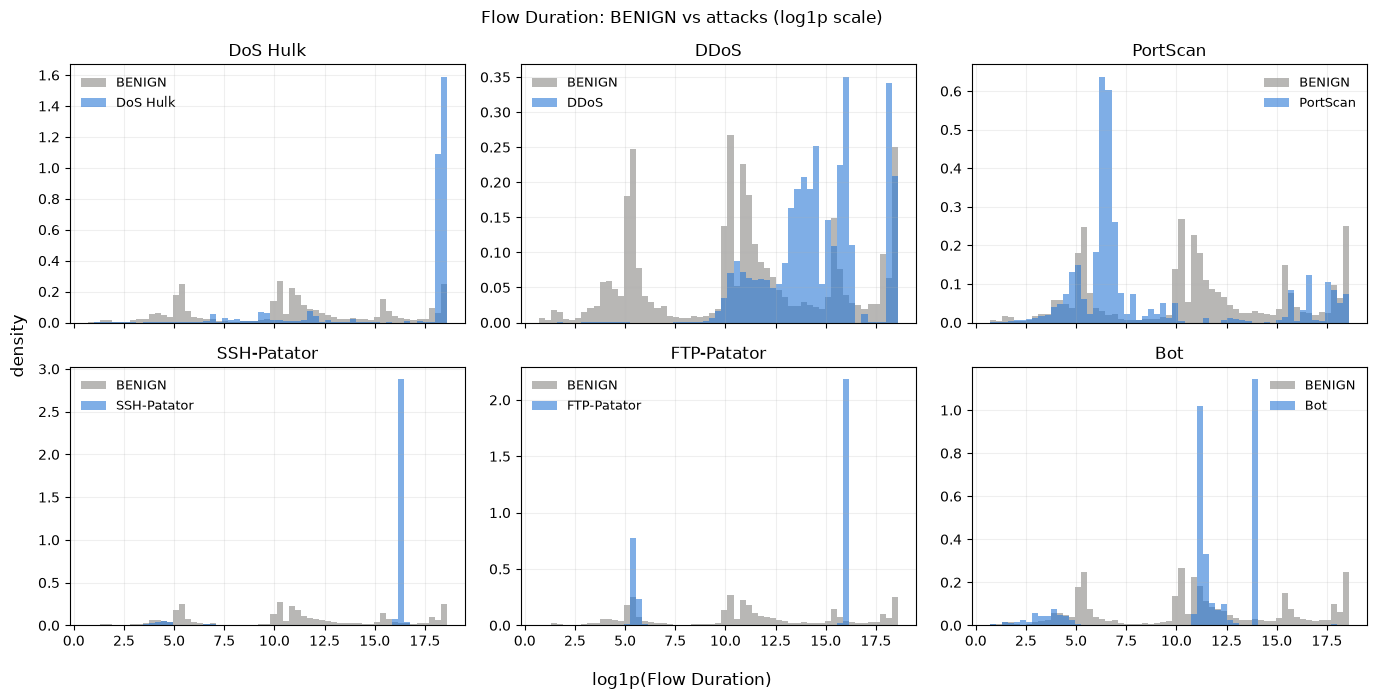

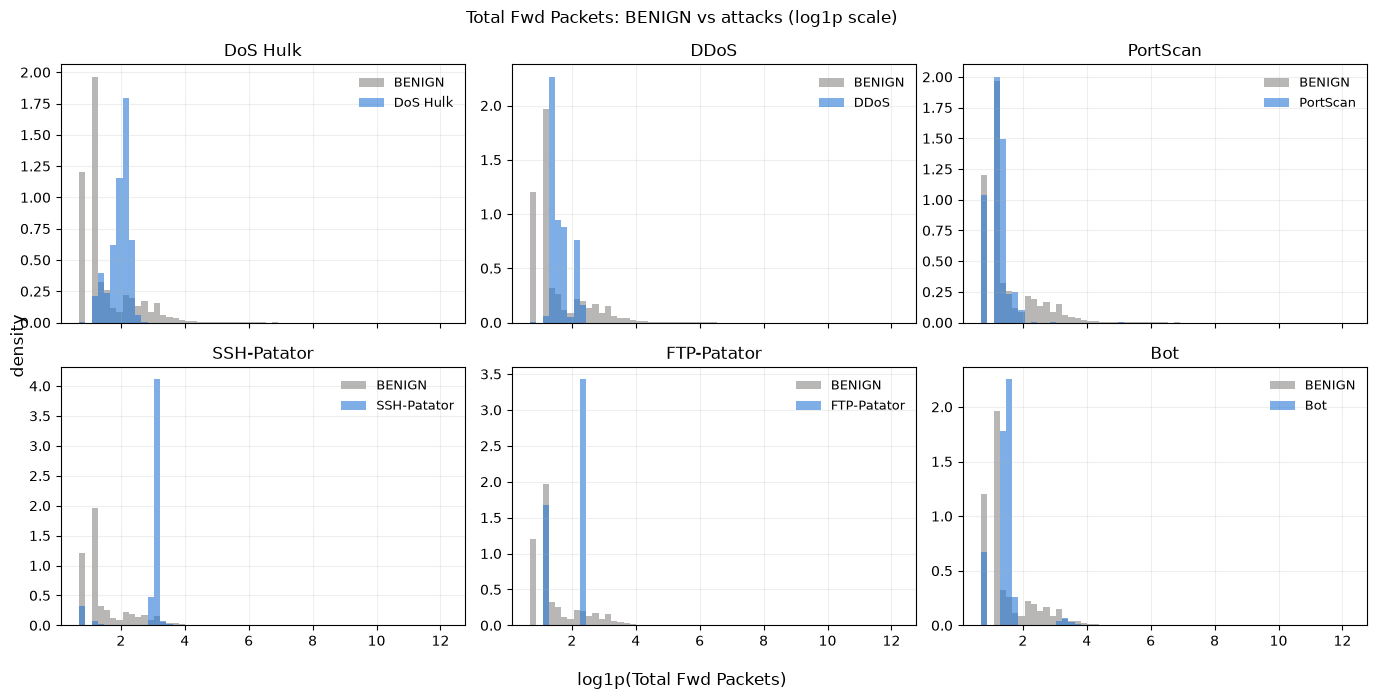

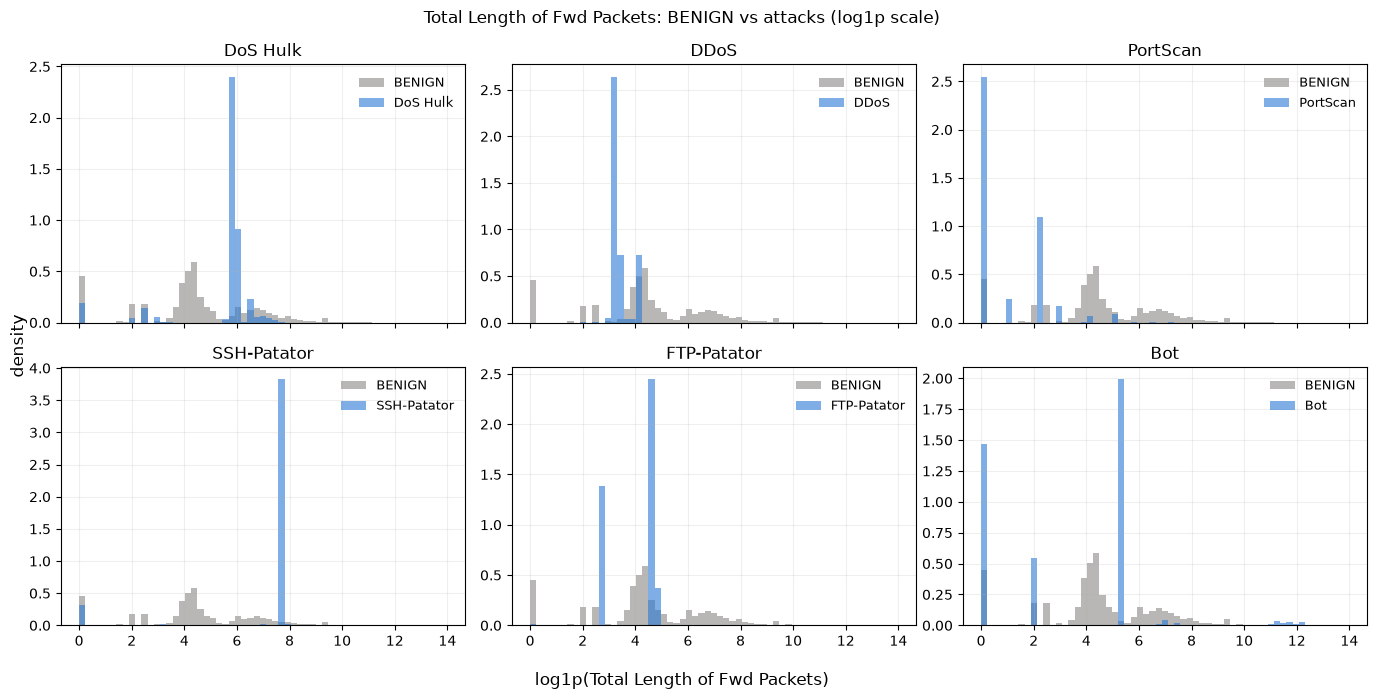

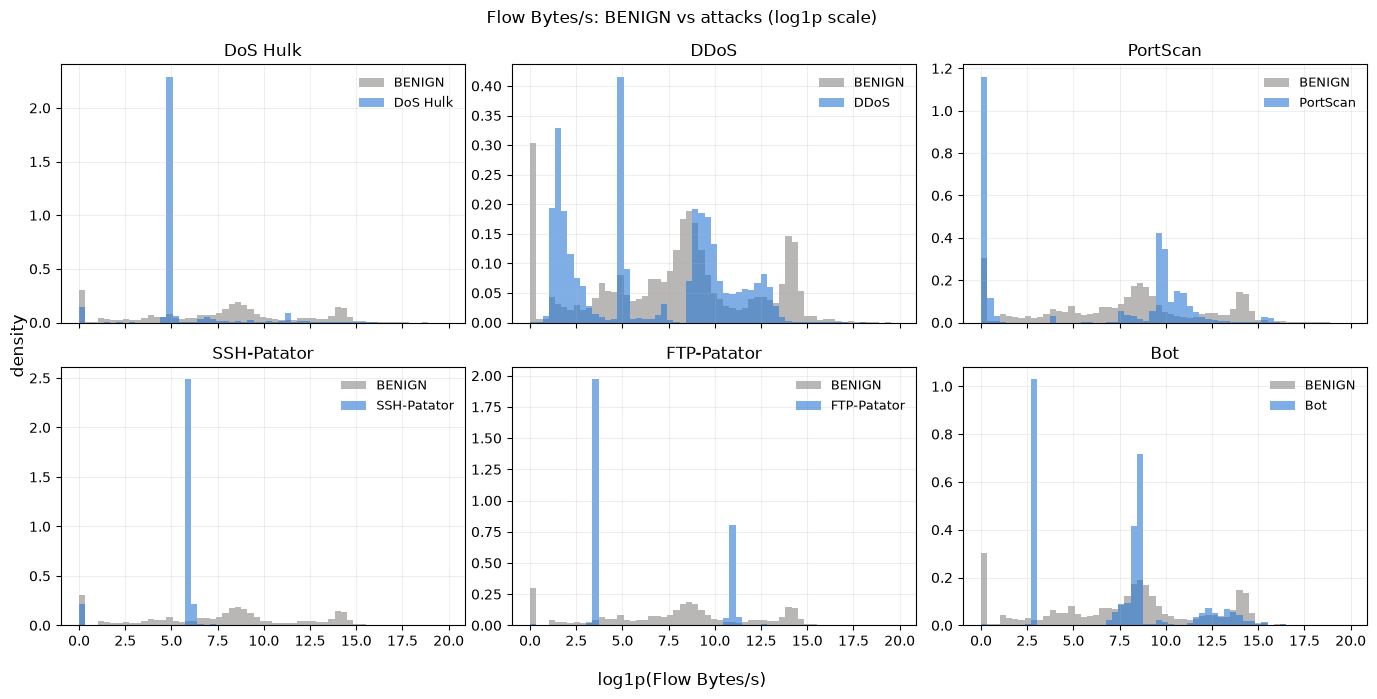

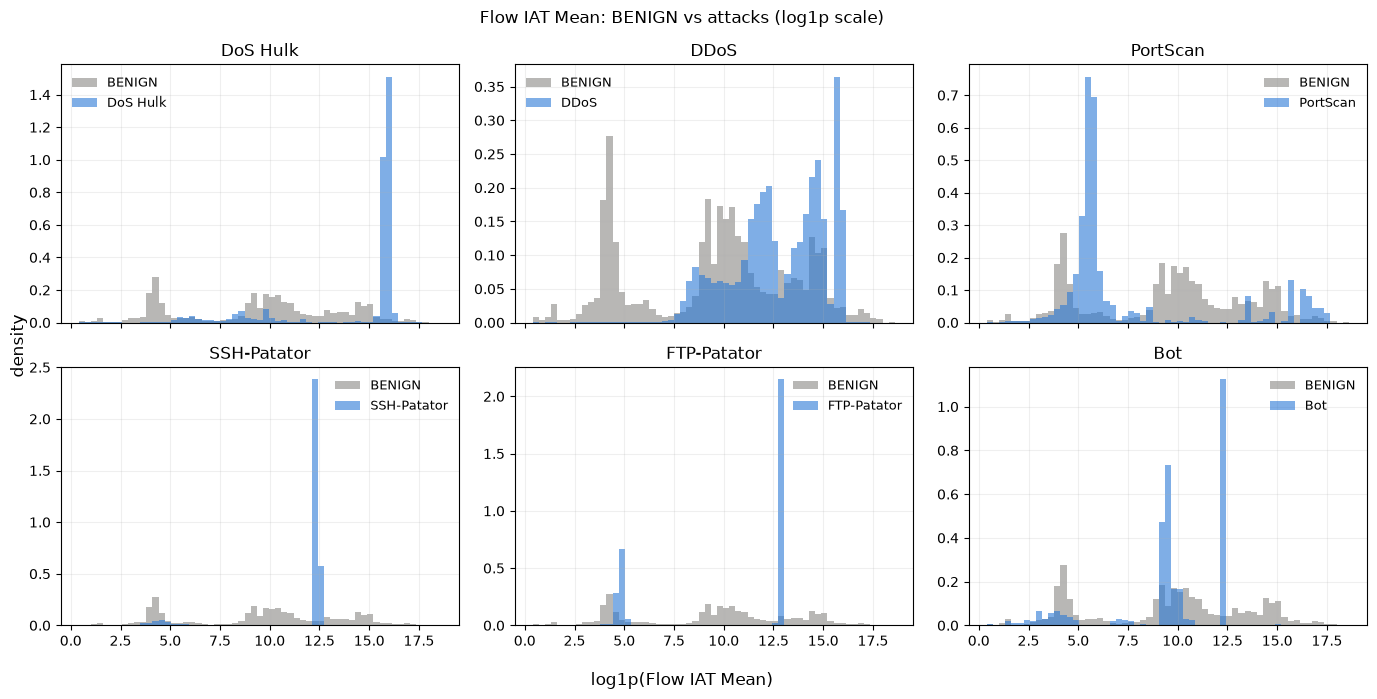

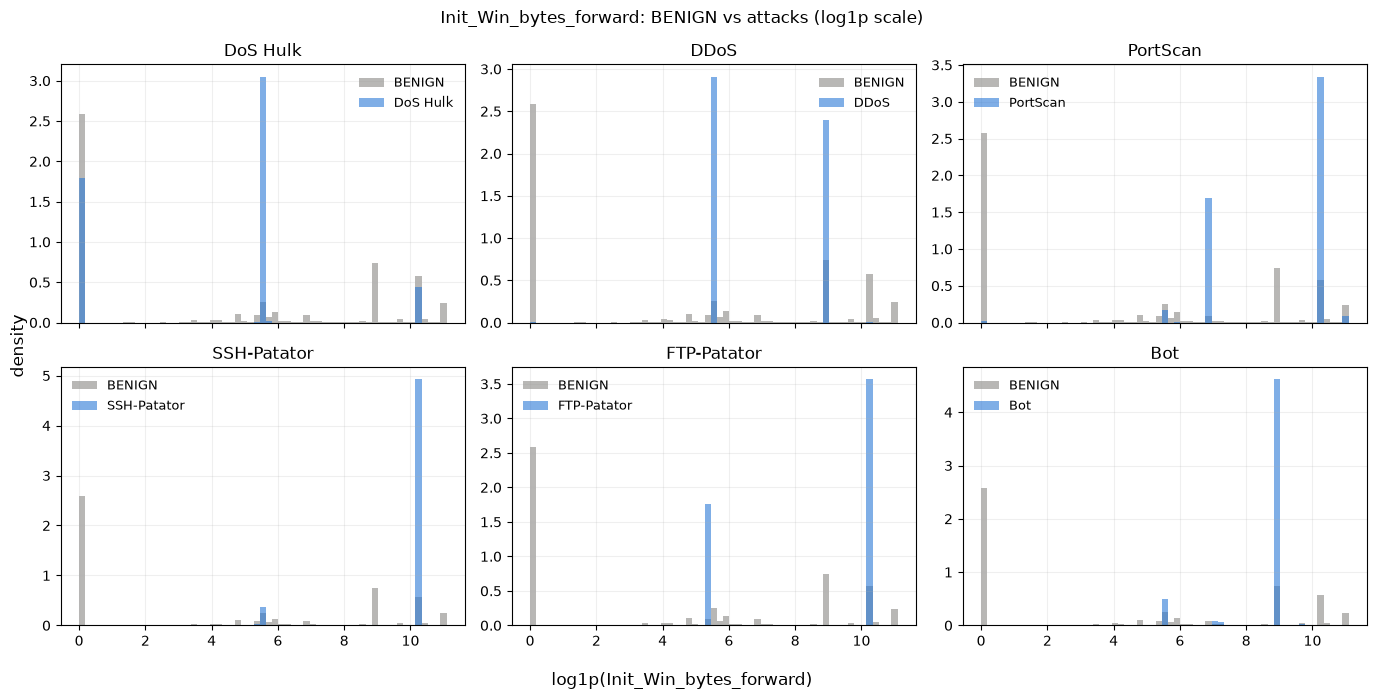

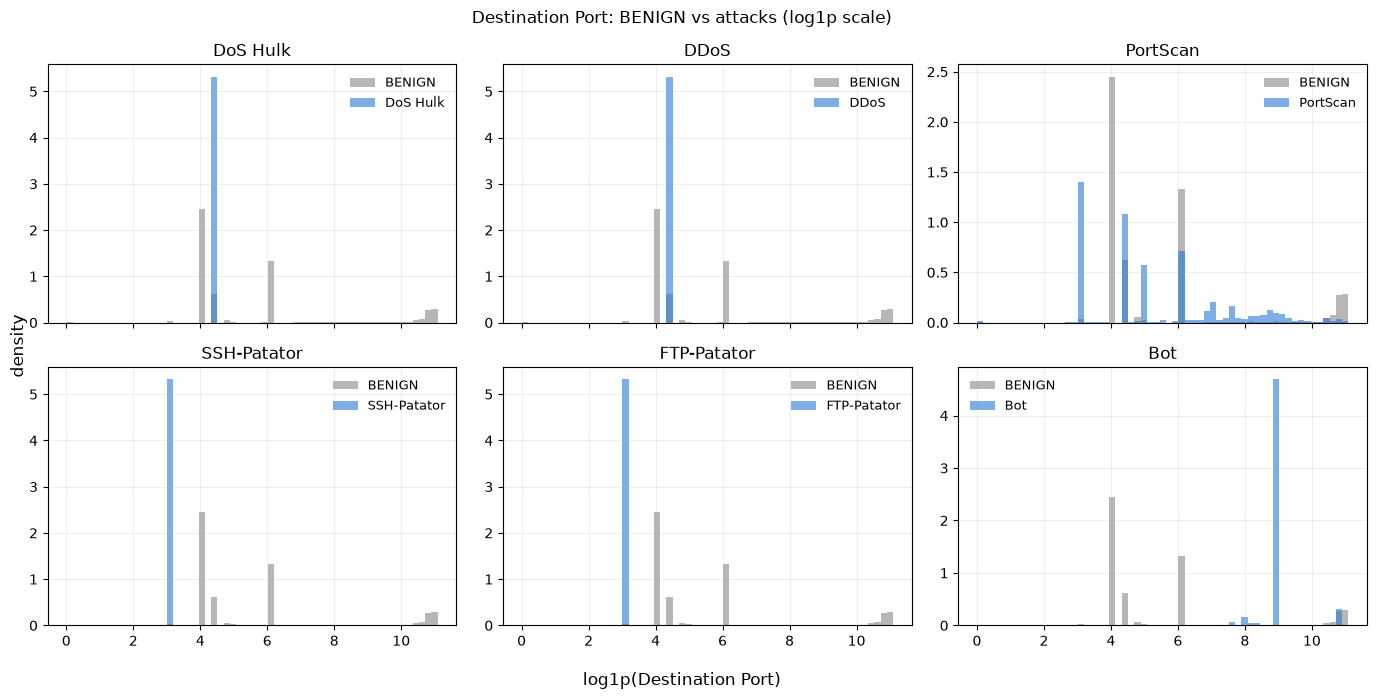

In [3]:
FEATURES = ["Flow Duration", "Total Fwd Packets", "Total Length of Fwd Packets",
            "Flow Bytes/s", "Flow IAT Mean", "Init_Win_bytes_forward", "Destination Port"]
ATTACKS = ["DoS Hulk", "DDoS", "PortScan", "SSH-Patator", "FTP-Patator", "Bot"]
LABELS = ["BENIGN"] + ATTACKS

# keep only the columns/labels we need, shuffle, then take the first 50k rows of each label
sub = df_flow.loc[df_flow["Label"].isin(LABELS), FEATURES + ["Label"]]
sample = sub.sample(frac=1, random_state=42).groupby("Label").head(50_000)
print(sample["Label"].value_counts().to_string())

def log1p_clip(x):
    """Clip negatives to 0, then log1p (log(1 + x)) so 0 stays 0."""
    return np.log1p(x.clip(lower=0))

for feat in FEATURES:
    values = log1p_clip(sample[feat])
    bins = np.linspace(values.min(), values.max(), 60)   # same bins in every panel
    benign = values[sample["Label"] == "BENIGN"]

    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
    for ax, attack in zip(axes.flat, ATTACKS):
        ax.hist(benign, bins=bins, density=True, color=GREY, alpha=0.7, label="BENIGN")
        ax.hist(values[sample["Label"] == attack], bins=bins, density=True,
                color=PALETTE[0], alpha=0.6, label=attack)
        ax.set_title(attack)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(alpha=0.2)
    fig.suptitle(f"{feat}: BENIGN vs attacks (log1p scale)")
    fig.supxlabel(f"log1p({feat})")
    fig.supylabel("density")
    fig.tight_layout()

    fname = re.sub(r"[^A-Za-z0-9]+", "_", feat).strip("_").lower()   # e.g. "flow_bytes_s"
    fig.savefig(FIG_DIR / f"dist_{fname}.png", dpi=120)
    plt.show()

In [4]:
# median of each feature per label (on all df_flow rows, not just the sample)
medians = df_flow[df_flow["Label"].isin(LABELS)].groupby("Label")[FEATURES].median().loc[LABELS]
print(medians.round(1).to_string())

             Flow Duration  Total Fwd Packets  Total Length of Fwd Packets  Flow Bytes/s  Flow IAT Mean  Init_Win_bytes_forward  Destination Port
Label                                                                                                                                            
BENIGN             51705.0                2.0                         74.0        3883.1        22231.5                    60.0              80.0
DoS Hulk        86419475.0                6.0                        354.0         123.9      7215206.4                   251.0              80.0
DDoS             1879158.0                4.0                         26.0         160.1       489490.8                   256.0              80.0
PortScan             694.5                2.0                          0.0        5047.3          295.5                 29200.0             139.0
SSH-Patator     12029788.0               21.0                       2008.0         389.4       230951.9                 2920

## 3. Time (df_full)

The `Timestamp` strings differ between files (`3/7/2017 8:55` vs `03/07/2017 08:55:58`), so we parse
each `day_file` separately with `dayfirst=True` (3/7 = 3 July) and `format="mixed"`.
Speed trick: there are far fewer unique timestamp strings than rows, so we parse each unique string once and map back.

In [5]:
def parse_ts(s):
    """Parse one file's timestamp strings: parse unique values once, then map back to all rows."""
    uniq = s.unique()
    parsed = pd.to_datetime(pd.Series(uniq), dayfirst=True, format="mixed", errors="coerce")
    lookup = pd.Series(parsed.values, index=uniq)
    return s.map(lookup)

df_full["ts_raw"] = df_full.groupby("day_file")["Timestamp"].transform(parse_ts)
print("rows that failed to parse:", df_full["ts_raw"].isna().sum())

rows that failed to parse: 0


In [6]:
# Are afternoon hours written as 1, 2, 3... (12-hour clock without AM/PM)?
hours = df_full.groupby("day_file")["ts_raw"].agg(
    date=lambda t: t.dt.date.iloc[0],
    min_hour=lambda t: t.dt.hour.min(),
    max_hour=lambda t: t.dt.hour.max(),
    hours_seen=lambda t: sorted(t.dt.hour.unique()),
)
print(hours.to_string())

                                                                   date  min_hour  max_hour                         hours_seen
day_file                                                                                                                      
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv             2017-07-07         3         5                          [3, 4, 5]
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv         2017-07-07         1         3                          [1, 2, 3]
Friday-WorkingHours-Morning.pcap_ISCX.csv                    2017-07-07         8        12                 [8, 9, 10, 11, 12]
Monday-WorkingHours.pcap_ISCX.csv                            2017-07-03         1        12  [1, 2, 3, 4, 5, 8, 9, 10, 11, 12]
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  2017-07-06         1         5                    [1, 2, 3, 4, 5]
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv       2017-07-06         8        12                 [8,

### Fix: the timestamps use a 12-hour clock without AM/PM

The output above shows it clearly: the `Afternoon` files only contain hours 1–5 (e.g. the PortScan file runs
from 1:00 to 3:xx), and every full-day file jumps from 12 back to 1. Capture ran roughly 08:30–17:15 every day,
so an hour of **1–7 can only be the afternoon**. Hours 8–12 are already right (8–11 morning, 12 noon).

Fix: `ts = ts_raw + 12 hours` when `hour < 8`. The dates themselves parse correctly with `dayfirst=True`
(3–7 July 2017, Monday–Friday). After the fix, the attack times below line up with the official CIC schedule.

In [7]:
is_pm = df_full["ts_raw"].dt.hour < 8          # 1-7 o'clock = afternoon
df_full["ts"] = df_full["ts_raw"] + pd.to_timedelta(is_pm.astype(int) * 12, unit="h")
df_full["day"] = df_full["ts"].dt.day_name()

# check: each file should now cover a sensible working-hours range
print(df_full.groupby("day_file")["ts"].agg(["min", "max"]).to_string())

                                                                            min                 max
day_file                                                                                           
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv            2017-07-07 15:30:00 2017-07-07 17:02:00
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv        2017-07-07 13:00:00 2017-07-07 15:29:00
Friday-WorkingHours-Morning.pcap_ISCX.csv                   2017-07-07 08:59:00 2017-07-07 12:59:00
Monday-WorkingHours.pcap_ISCX.csv                           2017-07-03 08:55:58 2017-07-03 17:01:34
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv 2017-07-06 13:00:00 2017-07-06 17:04:00
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv      2017-07-06 08:59:00 2017-07-06 12:59:00
Tuesday-WorkingHours.pcap_ISCX.csv                          2017-07-04 08:53:00 2017-07-04 17:00:00
Wednesday-workingHours.pcap_ISCX.csv                        2017-07-05 08:42:00 2017-07-05 17:10:00


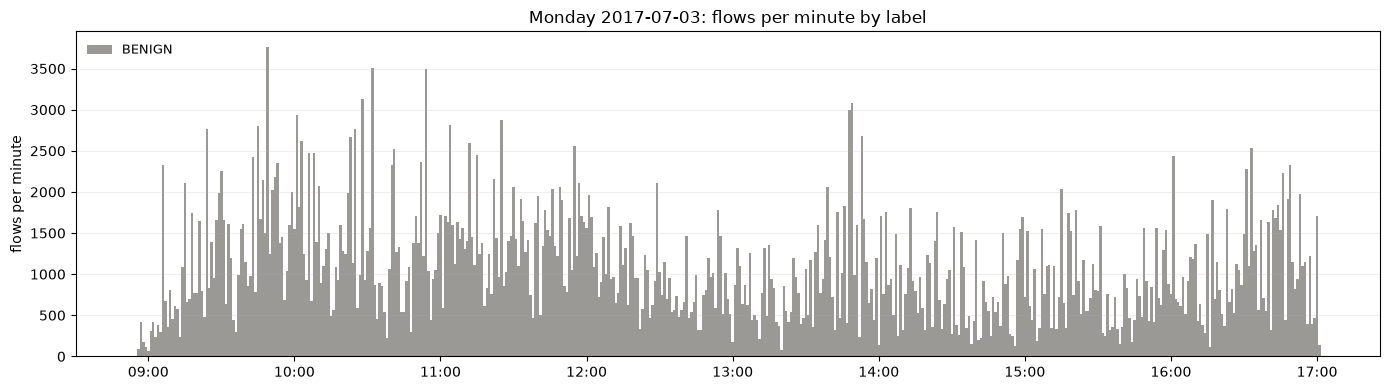

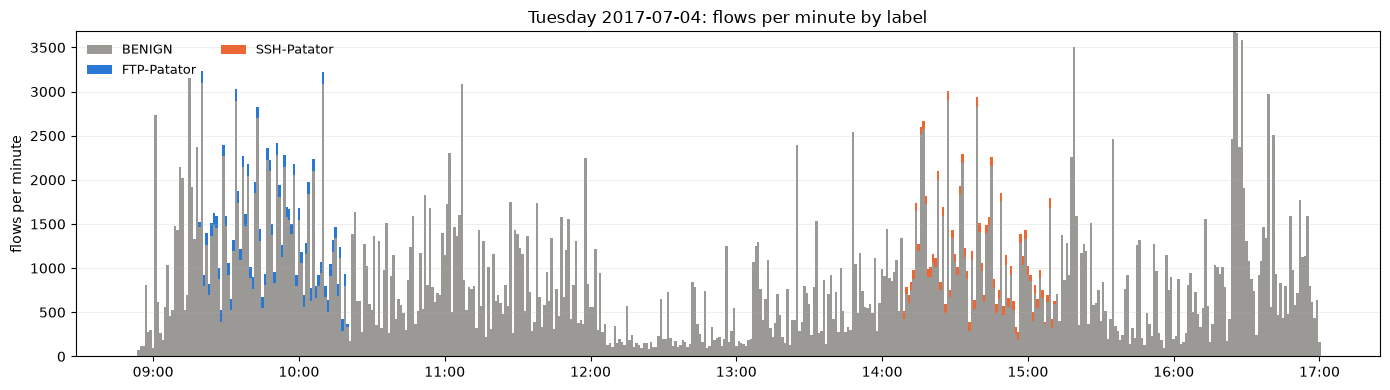

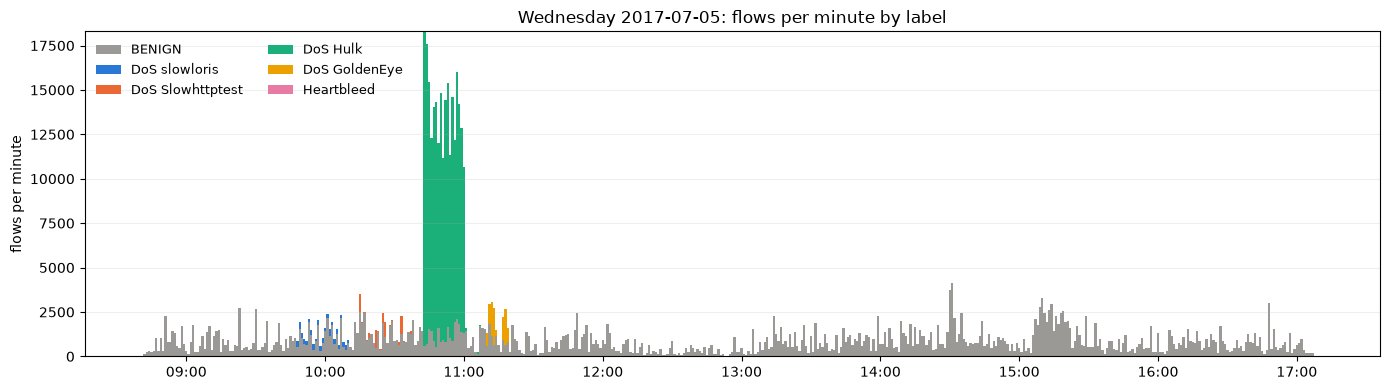

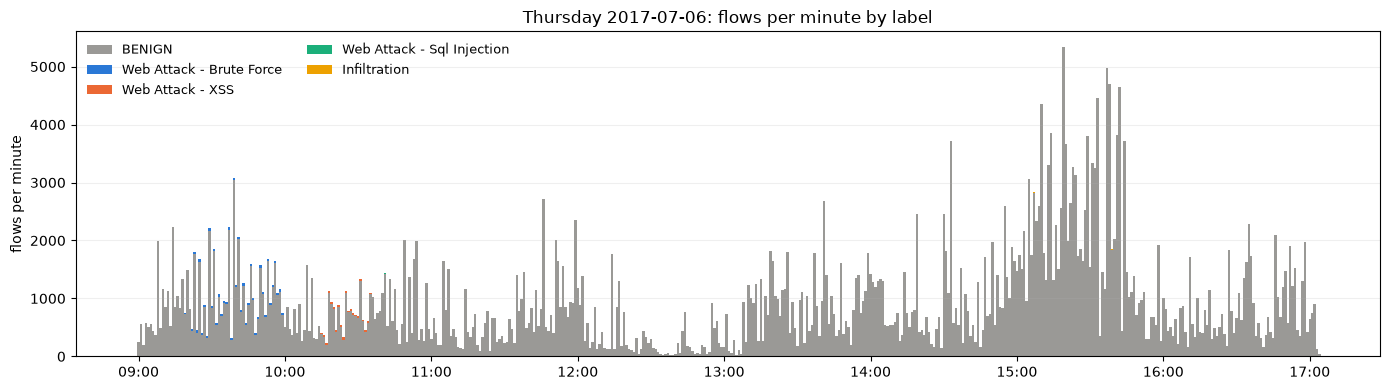

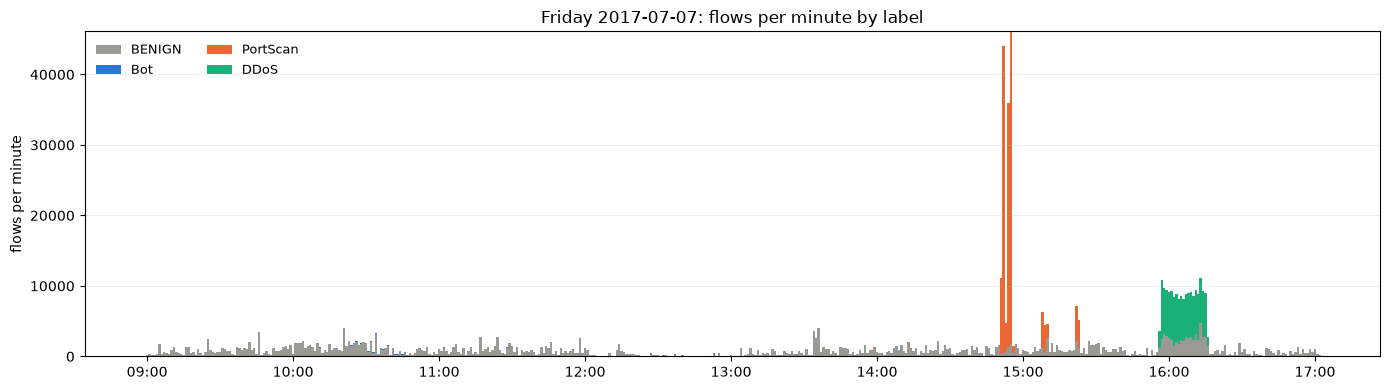

In [8]:
# flows per minute for each day, stacked by label (BENIGN grey at the bottom)
df_full["minute"] = df_full["ts"].dt.floor("min")

for day in ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]:
    d = df_full[df_full["day"] == day]
    counts = pd.crosstab(d["minute"], d["Label"])          # rows = minutes, cols = labels

    # attacks in order of first appearance, each with its own colour
    attacks = d[d["Label"] != "BENIGN"].groupby("Label")["ts"].min().sort_values().index.tolist()
    colors = {"BENIGN": GREY, **dict(zip(attacks, PALETTE))}

    fig, ax = plt.subplots(figsize=(14, 4))
    bottom = np.zeros(len(counts))
    for label in ["BENIGN"] + attacks:
        ax.bar(counts.index, counts[label], bottom=bottom, width=1 / 1440,   # 1 minute wide (units = days)
               color=colors[label], label=label)
        bottom += counts[label].values
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_title(f"{day} {d['ts'].dt.date.iloc[0]}: flows per minute by label")
    ax.set_ylabel("flows per minute")
    ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"time_{day.lower()}.png", dpi=120)
    plt.show()

In [9]:
# first and last timestamp of every attack label, next to the official CIC schedule
official = {
    "FTP-Patator": "Tue 09:20-10:20", "SSH-Patator": "Tue 14:00-15:00",
    "DoS slowloris": "Wed 09:47-11:23 (DoS)", "DoS Slowhttptest": "Wed 09:47-11:23 (DoS)",
    "DoS Hulk": "Wed 09:47-11:23 (DoS)", "DoS GoldenEye": "Wed 09:47-11:23 (DoS)",
    "Heartbleed": "Wed 15:12-15:32",
    "Web Attack - Brute Force": "Thu 09:20-10:42 (web)", "Web Attack - XSS": "Thu 09:20-10:42 (web)",
    "Web Attack - Sql Injection": "Thu 09:20-10:42 (web)", "Infiltration": "Thu 14:19-15:45",
    "Bot": "Fri 10:02-11:02", "PortScan": "Fri 13:55-15:29", "DDoS": "Fri 15:56-16:16",
}
attacks_only = df_full[df_full["Label"] != "BENIGN"]
first_last = attacks_only.groupby("Label").agg(
    day=("day", "first"), first=("ts", "min"), last=("ts", "max"), flows=("ts", "size"))
first_last = first_last.sort_values("first")                 # chronological order
first_last["first"] = first_last["first"].dt.strftime("%H:%M")  # show just the clock time
first_last["last"] = first_last["last"].dt.strftime("%H:%M")
first_last["official"] = first_last.index.map(official)
print(first_last.to_string())

                                  day  first   last   flows               official
Label                                                                             
FTP-Patator                   Tuesday  09:17  10:30    7935        Tue 09:20-10:20
SSH-Patator                   Tuesday  14:09  15:11    5897        Tue 14:00-15:00
DoS slowloris               Wednesday  09:01  14:25    5796  Wed 09:47-11:23 (DoS)
DoS Slowhttptest            Wednesday  10:15  10:37    5499  Wed 09:47-11:23 (DoS)
DoS Hulk                    Wednesday  10:43  11:07  230124  Wed 09:47-11:23 (DoS)
DoS GoldenEye               Wednesday  11:10  11:19   10293  Wed 09:47-11:23 (DoS)
Heartbleed                  Wednesday  15:12  15:32      11        Wed 15:12-15:32
Web Attack - Brute Force     Thursday  09:15  10:00    1507  Thu 09:20-10:42 (web)
Web Attack - XSS             Thursday  10:15  10:35     652  Thu 09:20-10:42 (web)
Web Attack - Sql Injection   Thursday  10:40  10:42      21  Thu 09:20-10:42 (web)
Infi

## 4. Source and destination IPs (df_full)

Who sends the attack traffic, and who receives it? (Note: CICFlowMeter's "source" is whoever sent the first
packet of the flow, so a victim can sometimes show up as a source.)

In [10]:
attack_labels = df_full.loc[df_full["Label"] != "BENIGN", "Label"].value_counts().index

for label in attack_labels:
    g = df_full[df_full["Label"] == label]
    print(f"=== {label} ({len(g):,} flows) ===")
    for col in ["Source IP", "Destination IP"]:
        top = g[col].value_counts().head(5)
        table = pd.DataFrame({"flows": top, "% of label": (top / len(g) * 100).round(1)})
        print(f"top 5 {col}:")
        print(table.to_string())
    print()

=== DoS Hulk (230,124 flows) ===
top 5 Source IP:
             flows  % of label
Source IP                     
172.16.0.1  230124       100.0
top 5 Destination IP:
                 flows  % of label
Destination IP                    
192.168.10.50   230124       100.0

=== PortScan (158,804 flows) ===
top 5 Source IP:
             flows  % of label
Source IP                     
172.16.0.1  158804       100.0
top 5 Destination IP:
                 flows  % of label
Destination IP                    
192.168.10.50   158804       100.0

=== DDoS (128,025 flows) ===
top 5 Source IP:
                flows  % of label
Source IP                        
172.16.0.1     128022       100.0
192.168.10.50       3         0.0
top 5 Destination IP:
                 flows  % of label
Destination IP                    
192.168.10.50   128022       100.0
172.16.0.1           3         0.0

=== DoS GoldenEye (10,293 flows) ===
top 5 Source IP:
            flows  % of label
Source IP                    

In [11]:
all_src = df_full["Source IP"].unique()
attack_src = df_full.loc[df_full["Label"] != "BENIGN", "Source IP"].unique()
print("unique Source IPs overall:      ", len(all_src))
print("Source IPs that send any attack:", len(attack_src))
print(sorted(attack_src))

unique Source IPs overall:       17002
Source IPs that send any attack: 10
['172.16.0.1', '192.168.10.12', '192.168.10.14', '192.168.10.15', '192.168.10.17', '192.168.10.5', '192.168.10.50', '192.168.10.8', '192.168.10.9', '205.174.165.73']


In [12]:
# top 10 source IPs by flow count: how many flows of each label do they send?
top10 = df_full["Source IP"].value_counts().head(10).index
top = df_full[df_full["Source IP"].isin(top10)]
ct = pd.crosstab(top["Source IP"], top["Label"])
ct = ct.loc[top10]                    # keep the "most flows first" order
ct = ct.loc[:, ct.sum() > 0]          # drop labels these IPs never send
print(ct.to_string())

Label          BENIGN  Bot    DDoS  DoS GoldenEye  DoS Hulk  DoS Slowhttptest  DoS slowloris  FTP-Patator  Heartbleed  Infiltration  PortScan  SSH-Patator  Web Attack - Brute Force  Web Attack - Sql Injection  Web Attack - XSS
Source IP                                                                                                                                                                                                                         
172.16.0.1       3599    0  128022          10293    230124              5499           5796         7935          11             0    158804         5897                      1507                          21               652
192.168.10.3   298941    0       0              0         0                 0              0            0           0             0         0            0                         0                           0                 0
192.168.10.8   214731  271       0              0         0                 0              0

In [13]:
# PortScan: distinct destination ports per source IP per minute
ps = df_full[df_full["Label"] == "PortScan"]
per_min = (ps.groupby(["Source IP", "minute"])
             .agg(distinct_dst_ports=("Destination Port", "nunique"), flows=("Destination Port", "size"))
             .sort_values("distinct_dst_ports", ascending=False))
print(per_min.head(10).to_string())

# for comparison: the same statistic for BENIGN traffic
bn = df_full[df_full["Label"] == "BENIGN"]
bn_ports = bn.groupby(["Source IP", "minute"])["Destination Port"].nunique()
print("\nBENIGN distinct dst ports per source per minute: median",
      bn_ports.median(), "| 99th pct", bn_ports.quantile(0.99), "| max", bn_ports.max())

                                distinct_dst_ports  flows
Source IP  minute                                        
172.16.0.1 2017-07-07 15:08:00                 999   4999
           2017-07-07 15:23:00                 999   4005
           2017-07-07 15:10:00                 999   2004
           2017-07-07 14:51:00                 998  10908
           2017-07-07 15:09:00                 998   4022
           2017-07-07 15:22:00                 998   5011
           2017-07-07 14:54:00                 997  34594
           2017-07-07 14:53:00                 996   3953
           2017-07-07 14:52:00                 996  43577
           2017-07-07 14:55:00                 996  44368

BENIGN distinct dst ports per source per minute: median 1.0 | 99th pct 13.0 | max 1894


# EDA findings

**1. Saved data**
- Parquet files load correctly: `df_full` 2,827,761 × 69, `df_flow` 2,233,050 × 69, label counts as expected.
- Deduplication hits some attacks hard: PortScan 158,804 → 1,850 (99% are identical flows), DoS Hulk 230k → 173k, SSH-Patator 5,897 → 3,219. Scans and floods repeat the same flow over and over.

**2. Which features separate attacks from BENIGN**
- `Init_Win_bytes_forward` is the strongest: BENIGN is spread out (median 60, many 0/-1), each attack sits on one spike (29200 for PortScan/SSH/FTP, 8192 for Bot, ~250 for DoS/DDoS). Careful: those spikes are a fingerprint of the attacker's OS/tool, so they may not carry over to other networks.
- `Flow Duration` / `Flow IAT Mean`: DoS Hulk (median ~86 s), SSH-Patator (~12 s) and FTP-Patator (~9 s) are much longer than BENIGN (~0.05 s); PortScan is much shorter (~0.7 ms).
- `Total Length of Fwd Packets`: PortScan sends 0 payload bytes; SSH-Patator ~2 KB; BENIGN ~74 B.
- `Flow Bytes/s`: lower for DoS/DDoS/FTP-Patator; overlaps BENIGN for Bot and PortScan.
- `Total Fwd Packets`: weak, the medians (2–21) overlap a lot.
- `Destination Port` separates SSH (22), FTP (21) and Bot (8080) perfectly, but only because each attack targets one service. DoS/DDoS use port 80 just like BENIGN. It describes the service rather than the behaviour, so it is a shortcut risk.
- Bot is the closest to BENIGN on almost every feature, so expect it to be the hardest class.

**3. Time**
- The timestamps use a **12-hour clock without AM/PM** (afternoon files show hours 1–5). Fixed with +12 h for hours 1–7, giving the `ts` column. 0 rows failed to parse.
- After the fix, the attack windows match the official CIC schedule to within a few minutes. Each attack type is **one tight block on one day**. Monday is all BENIGN. Bot is the most spread out (09:34–12:59, ~25% of its flows outside 10:02–11:02).
- Heartbleed (11), SQL Injection (21) and Infiltration (36) are too small to see on the plots.
- What this means for the split:
  - A **random** split leaks, because near-identical flows from the same burst land in both train and test.
  - A plain **split by day** puts some attack types only in test, so the model is scored on attacks it never saw in training.
  - A fair time-based option: split **chronologically inside each attack block / day** (earlier part → train, later part → test). That way every attack type is in both sets, and test is always later than train.

**4. IPs**
- 17,002 unique Source IPs, but only **10** ever send attack traffic.
- `172.16.0.1` sends ~100% of all DoS, DDoS, PortScan, Patator, Web and Heartbleed flows. That is the firewall NAT in front of the attacker `205.174.165.73`. Almost all of these flows go to one victim, `192.168.10.50`. Bot and Infiltration come from internal hosts (`192.168.10.x`) talking to `205.174.165.73`.
- The other busy source IPs are almost all BENIGN with a few Bot flows. Even `172.16.0.1` also sends 3,599 BENIGN flows.
- **IPs must never be model inputs.** The model would just learn "172.16.0.1 = attack" and score almost perfectly here, then fail in the real world, where attackers change IPs or hide behind NAT/proxies. The same goes for `Flow ID`, `Source Port` and `Timestamp`. Use IPs only as a **grouping key** for window features, never as a feature.
- PortScan: `172.16.0.1` hits **~1,000 distinct destination ports per minute**, versus a BENIGN median of 1 (99th percentile 13). A per-source, per-minute "distinct destination ports" window feature is therefore a very strong scan signal, which confirms the per-source window idea. (One BENIGN source/minute reaches 1,894 ports, worth a look later.)